# WD-GPR-SR — Wide-and-Deep Sparse Gaussian Process with Symbolic Residual Correction

This notebook trains and evaluates the proposed battery State-of-Health (SOH) model on the same `data/unified.parquet` source, cycle aggregation, feature list, train-only preprocessing and Leave-One-Cell-Out (LOCO) folds used by the 13 baseline notebooks.

**Target:** cycle-level `soh_pct` (SOH in percentage points).

**Outputs:**
- `WD-GPR-SR/results/`: LOCO predictions, fold/overall metrics, ablation results, XAI tables and plots.
- `models/wd_gpr_sr.joblib`: final all-labelled-cell inference bundle.

The notebook does not modify baseline notebooks, baseline metrics or baseline model artifacts.

## Research formulation and evaluation safeguards

### Wide-and-deep sparse GP

The wide branch is a learned linear projection and the deep branch is a nonlinear feature extractor. They define an additive covariance:

\[
k(x,x') = \sigma_w^2\langle W x+b, W x'+b\rangle +
\sigma_d^2\exp\left[-\frac12\sum_j\frac{(\phi_\theta(x)_j-\phi_\theta(x')_j)^2}{\ell_j^2}\right].
\]

A sparse variational GP approximates the posterior using inducing points. Its parameters and both feature branches are learned jointly by maximizing the variational evidence lower bound (ELBO):

\[
\mathcal L_{ELBO}=\mathbb E_q[\log p(y\mid f)]-KL[q(u)\Vert p(u)].
\]

### Uncertainty-weighted symbolic residual

Inner `GroupKFold` splits are formed **only from the current outer training cells**. Each inner validation cell receives an out-of-cell GP prediction. Symbolic regression learns the residual

\[
e_i=y_i-\mu_{GP}(x_i),\qquad
\hat y(x)=\mu_{GP}(x)+r_{SR}(x,\tilde\sigma_{GP}(x)).
\]

The symbolic fitness is uncertainty-emphasized: samples with larger GP predictive standard deviation receive greater weight, using `clip(sigma / median(sigma), 0.25, 4.0)`. A parsimony penalty discourages unnecessarily large equations. This weighting convention is explicitly recorded in the results; it is a design choice, not a universal calibration rule.

### Fairness and leakage control

- Outer folds are the same sorted-cell LOCO folds and `RANDOM_SEED=42` used by the baselines.
- The copied baseline preprocessing cell fits numeric imputation, missing indicators, scaling, categorical imputation/one-hot encoding and target scaling on each outer training fold only.
- The outer held-out cell is never used to fit the GP, symbolic equation, feature selection or any hyperparameter.
- The symbolic residual model is trained from inner cross-fitted predictions, not in-sample GP residuals.
- The final artifact is refitted on all labelled NASA/CALCE cycles only after LOCO evaluation.

**Performance cannot be guaranteed in advance.** The proposed model is designed to improve accuracy and provide uncertainty plus an equation, but whether it beats every baseline must be determined from the held-out-cell results. Do not tune against the outer test folds.

## 1. Install dependencies

Run once in the notebook environment. If PyTorch is already installed with GPU support, do not replace it with a generic wheel.

In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib joblib pyarrow psutil gpytorch gplearn shap lime

Note: you may need to restart the kernel to use updated packages.


## 2. Imports, paths and reproducibility

The following imports and automatic project/data discovery follow the baseline notebooks.

In [2]:
from pathlib import Path
import os, re, json, time, random, warnings, math, numbers
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, Matern, WhiteKernel
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

try:
    import psutil
except ImportError:
    psutil = None

try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
except ImportError:
    torch = nn = DataLoader = TensorDataset = None

try:
    import gpytorch
except ImportError:
    gpytorch = None

RANDOM_SEED = 42
TARGET = 'soh_pct'
SEQUENCE_LENGTH = 8
MAX_EXACT_GP_SAMPLES = 1500
DATA_DIR_OVERRIDE = None  # Set to Path('/absolute/path/to/PBL/data') only if auto-discovery fails.


def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception:
            pass

set_seed(RANDOM_SEED)


def locate_data_dir(override=None):
    if override is not None:
        p = Path(override).expanduser().resolve()
        if not p.exists():
            raise FileNotFoundError(f'DATA_DIR_OVERRIDE does not exist: {p}')
        if not ((p / 'unified.parquet').exists() or (p / 'unified.csv').exists()):
            raise FileNotFoundError(f'No unified.parquet or unified.csv found in {p}')
        return p.parent, p
    cwd = Path.cwd().resolve()
    for root in [cwd, *cwd.parents]:
        for candidate in (root / 'data', root / 'PBL' / 'data'):
            if candidate.is_dir() and ((candidate / 'unified.parquet').exists() or (candidate / 'unified.csv').exists()):
                return candidate.parent, candidate
    raise FileNotFoundError(
        'Could not find data/unified.parquet. Put this notebook somewhere under your PBL project, '
        'or set DATA_DIR_OVERRIDE to the directory containing unified.parquet.'
    )

print('Seed:', RANDOM_SEED)
print('Working directory:', Path.cwd().resolve())
print('Torch:', torch.__version__ if torch is not None else 'not installed')
print('GPyTorch:', gpytorch.__version__ if gpytorch is not None else 'not installed')


try:
    from gplearn.genetic import SymbolicRegressor
    from gplearn.fitness import make_fitness
except ImportError as exc:
    raise ImportError("Install gplearn with: %pip install gplearn") from exc

if torch is None or gpytorch is None:
    raise ImportError("WD-GPR-SR requires PyTorch and GPyTorch. Install with: %pip install torch gpytorch")


/home/raj/Documents/Projects/PBL/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Seed: 42
Working directory: /home/raj/Documents/Projects/PBL/WD-GPR-SR
Torch: 2.15.0+cu132
GPyTorch: 1.15.2


## 3. Load unified measurements and build cycle-level samples

This is copied from the baseline preprocessing pipeline: same columns, cycle grouping, target construction, aggregation order and forbidden target-derived predictors.

In [3]:
NUMERIC_RAW_FEATURES = [
    'voltage_V', 'current_A', 'current_avg_A', 'temperature_C', 'soc_pct',
    'charge_counter_Ah', 'nominal_capacity_Ah', 'elapsed_time_s',
    'impedance_re_ohm', 'impedance_rct_ohm', 'cycle_count', 'plugged',
]
CATEGORICAL_RAW_FEATURES = ['source_dataset', 'operation', 'battery_technology']
AGGREGATIONS = ['mean', 'std', 'min', 'max', 'first', 'last']


def load_measurements(data_dir=None):
    project_root, data_path = locate_data_dir(data_dir)
    parquet_path = data_path / 'unified.parquet'
    csv_path = data_path / 'unified.csv'
    if parquet_path.exists():
        try:
            frame = pd.read_parquet(
                parquet_path,
                filters=[('source_dataset', 'in', ['NASA', 'CALCE'])],
            )
        except Exception:
            frame = pd.read_parquet(parquet_path)
        source_path = parquet_path
    elif csv_path.exists():
        chunks = []
        for chunk in pd.read_csv(csv_path, chunksize=250_000, low_memory=False):
            if 'source_dataset' in chunk:
                keep = chunk['source_dataset'].astype(str).str.upper().isin(['NASA', 'CALCE'])
                if keep.any():
                    chunks.append(chunk.loc[keep])
        frame = pd.concat(chunks, ignore_index=True) if chunks else pd.DataFrame()
        source_path = csv_path
    else:
        raise FileNotFoundError('No unified.parquet or unified.csv found.')

    required = {'source_dataset', 'entity_id'}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'Unified file is missing required columns: {sorted(missing)}')
    frame['source_dataset'] = frame['source_dataset'].astype(str).str.upper()
    frame = frame[frame['source_dataset'].isin(['NASA', 'CALCE'])].copy()
    if frame.empty:
        raise ValueError('No NASA/CALCE rows found. Check source_dataset values in unified.parquet.')
    return frame, project_root, source_path


def cycle_number(value):
    if pd.isna(value):
        return np.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        found = re.findall(r'-?\d+(?:\.\d+)?', str(value))
        return float(found[-1]) if found else np.nan


def build_cycle_table(measurements, require_labels=True):
    """Aggregate measurement rows into chronological, cycle-level samples."""
    df = measurements.copy()
    for col in ['session_id', 'cycle_id', 'operation', 'timestamp_utc']:
        if col not in df:
            df[col] = pd.NA
    for col in ['source_dataset', 'entity_id']:
        df[col] = df[col].astype('string').fillna('UNKNOWN')
    df['session_id'] = df['session_id'].astype('string').fillna('')
    df['cycle_id'] = df['cycle_id'].astype('string').replace({'<NA>': pd.NA, '': pd.NA, 'nan': pd.NA})

    if TARGET not in df:
        df[TARGET] = np.nan
    df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')

    # Derive SOH only from measured capacity / nominal capacity when the source
    # provides those fields. Capacity fields are never predictors.
    if {'measured_capacity_Ah', 'nominal_capacity_Ah'}.issubset(df.columns):
        measured = pd.to_numeric(df['measured_capacity_Ah'], errors='coerce')
        nominal = pd.to_numeric(df['nominal_capacity_Ah'], errors='coerce')
        derived = 100.0 * measured / nominal.where(nominal > 0)
        df[TARGET] = df[TARGET].where(df[TARGET].notna(), derived)
    if {'capacity_raw_Ah', 'nominal_capacity_Ah'}.issubset(df.columns):
        raw = pd.to_numeric(df['capacity_raw_Ah'], errors='coerce')
        nominal = pd.to_numeric(df['nominal_capacity_Ah'], errors='coerce')
        derived = 100.0 * raw / nominal.where(nominal > 0)
        df[TARGET] = df[TARGET].where(df[TARGET].notna(), derived)
    df[TARGET] = df[TARGET].replace([np.inf, -np.inf], np.nan)

    cycle_key = df['cycle_id'].where(df['cycle_id'].notna(), df['session_id'])
    cycle_key = cycle_key.replace('', pd.NA)
    if 'cycle_count' in df:
        cc = pd.to_numeric(df['cycle_count'], errors='coerce').astype('string')
        cycle_key = cycle_key.where(cycle_key.notna(), cc)
    df['_cycle_key'] = cycle_key.fillna('NO_CYCLE_ID').astype('string')

    group_cols = ['source_dataset', 'entity_id', 'session_id', '_cycle_key']
    if require_labels:
        labelled = df.loc[df[TARGET].notna(), group_cols].drop_duplicates()
        if labelled.empty:
            raise ValueError(
                'No measured SOH/capacity labels were found in NASA/CALCE. '
                'Check the unified-data SOH labels and the capacity units/nominal-capacity assumptions.'
            )
        keys = pd.MultiIndex.from_frame(labelled)
        all_keys = pd.MultiIndex.from_frame(df[group_cols])
        df = df.loc[all_keys.isin(keys)].copy()

    raw_numeric = [c for c in NUMERIC_RAW_FEATURES if c in df.columns]
    raw_categorical = [c for c in CATEGORICAL_RAW_FEATURES if c in df.columns]

    rows = []
    for key, group in df.groupby(group_cols, sort=False, dropna=False):
        source, entity, session, cycle = key
        if 'timestamp_utc' in group:
            group = group.sort_values('timestamp_utc', kind='mergesort', na_position='last')
        labels = pd.to_numeric(group[TARGET], errors='coerce').dropna()
        if require_labels and labels.empty:
            continue
        row = {
            'source_dataset': str(source),
            'entity_id': str(entity),
            'session_id': str(session),
            'cycle_key': str(cycle),
            TARGET: float(labels.median()) if not labels.empty else np.nan,
            'n_measurements': int(len(group)),
            'cycle_index': cycle_number(cycle),
            'cycle_timestamp': pd.NaT,
        }
        for col in raw_categorical:
            vals = group[col].dropna().astype(str)
            row[col] = vals.mode().iloc[0] if not vals.empty else 'UNKNOWN'
        for col in raw_numeric:
            vals = pd.to_numeric(group[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
            if vals.notna().any():
                stats = {
                    'mean': vals.mean(), 'std': vals.std(), 'min': vals.min(),
                    'max': vals.max(), 'first': vals.iloc[0], 'last': vals.iloc[-1],
                }
            else:
                stats = {s: np.nan for s in AGGREGATIONS}
            for stat in AGGREGATIONS:
                row[f'{col}__{stat}'] = stats[stat]
        if 'timestamp_utc' in group:
            ts = pd.to_datetime(group['timestamp_utc'], errors='coerce', utc=True).dropna()
            row['cycle_timestamp'] = ts.min() if not ts.empty else pd.NaT
        rows.append(row)

    cycles = pd.DataFrame(rows)
    if cycles.empty:
        raise ValueError('Cycle aggregation produced no samples. Check cycle_id/session_id and labels.')
    cycles['cycle_index'] = pd.to_numeric(cycles['cycle_index'], errors='coerce')
    cycles = cycles.sort_values(
        ['source_dataset', 'entity_id', 'cycle_index', 'cycle_timestamp', 'cycle_key'],
        kind='mergesort', na_position='last'
    ).reset_index(drop=True)
    missing_idx = cycles['cycle_index'].isna()
    if missing_idx.any():
        cycles.loc[missing_idx, 'cycle_index'] = (
            cycles.loc[missing_idx].groupby(['source_dataset', 'entity_id'], sort=False).cumcount().astype(float)
        )
    cycles['cell_group'] = cycles['source_dataset'].astype(str) + '::' + cycles['entity_id'].astype(str)
    cycles = cycles.replace([np.inf, -np.inf], np.nan)
    if require_labels:
        cycles = cycles.loc[cycles[TARGET].notna()].reset_index(drop=True)
    return cycles


def get_feature_columns(cycles):
    numeric = [
        c for c in cycles.columns
        if c.endswith(tuple(f'__{s}' for s in AGGREGATIONS))
        and pd.to_numeric(cycles[c], errors='coerce').notna().any()
    ]
    numeric += [c for c in ['cycle_index', 'n_measurements'] if c in cycles.columns]
    categorical = [c for c in CATEGORICAL_RAW_FEATURES if c in cycles.columns]
    forbidden = {
        TARGET, 'capacity_raw_Ah', 'measured_capacity_Ah', 'source_file', 'entity_id',
        'cell_group', 'cycle_key', 'session_id', 'cycle_timestamp', '_cycle_key',
        'cycle_id', 'record_id',
    }
    numeric = [c for c in numeric if c not in forbidden]
    categorical = [c for c in categorical if c not in forbidden]
    if not numeric and not categorical:
        raise ValueError('No usable predictors were generated from the unified dataset.')
    return numeric, categorical


measurements, PROJECT_ROOT, UNIFIED_PATH = load_measurements(DATA_DIR_OVERRIDE)
cycles = build_cycle_table(measurements, require_labels=True)
NUMERIC_FEATURES, CATEGORICAL_FEATURES = get_feature_columns(cycles)
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print('Unified dataset:', UNIFIED_PATH)
print('Measurement rows (NASA/CALCE):', f'{len(measurements):,}')
print('Labelled cycle samples:', f'{len(cycles):,}')
print('Distinct battery cells:', cycles['cell_group'].nunique())
print('Numeric features:', len(NUMERIC_FEATURES))
print('Categorical features:', len(CATEGORICAL_FEATURES))
print('\nSamples by source and cell:')
display(cycles.groupby(['source_dataset', 'entity_id']).size().rename('cycles').to_frame())
print('\nSOH (%) summary:')
display(cycles[TARGET].describe().to_frame())

if cycles['cell_group'].nunique() < 2:
    raise ValueError('LOCO evaluation requires at least two distinct cells.')


Unified dataset: /home/raj/Documents/Projects/PBL/data/unified.parquet
Measurement rows (NASA/CALCE): 8,907,569
Labelled cycle samples: 8,642
Distinct battery cells: 47
Numeric features: 32
Categorical features: 3

Samples by source and cell:


cycles
source_dataset entity_id        
CALCE          CS2_33        434
               CS2_34        407
               CS2_35        381
               CS2_36        503
               CS2_37        501
               CS2_38        502
               CX2_16        469
               CX2_33        422
               CX2_34        438
               CX2_35        456
               CX2_36        492
               CX2_37        442
               CX2_38        426
NASA           B0005         168
               B0006         168
               B0007         168
               B0018         132
               B0025          28
               B0026          28
               B0027          28
               B0028          28
               B0029          40
               B0030          40
               B0031          40
               B0032          40
               B0033         197
               B0034         197
               B0036         197
               B0038          47
               B0039          47
               B0040          47
               B0041          67
               B0042         112
               B0043         112
               B0044         112
               B0045          72
               B0046          72
               B0047          72
               B0048          72
               B0049          25
               B0050          21
               B0051          25
               B0052           4
               B0053          56
               B0054         103
               B0055         102
               B0056         102


SOH (%) summary:


,soh_pct
count,8642.000000
mean,1263.453560
std,1292.848133
min,0.000000
25%,82.713996
50%,828.636367
75%,2257.015628
max,7259.259259


## 4. Shared train-only preprocessing, sequence generation and metrics

This is the same preprocessing and metric implementation used by the baseline notebooks. WD-GPR-SR operates on cycle-level rows, so no BiLSTM sequence transform is applied.

In [4]:
def make_preprocessor(numeric_features, categorical_features):
    transformers = []
    if numeric_features:
        try:
            numeric_imputer = SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
        except TypeError:
            numeric_imputer = SimpleImputer(strategy='median', add_indicator=True)
        numeric_pipe = Pipeline([
            ('imputer', numeric_imputer),
            ('scaler', StandardScaler()),
        ])
        transformers.append(('num', numeric_pipe, numeric_features))
    if categorical_features:
        try:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        except TypeError:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
        categorical_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder),
        ])
        transformers.append(('cat', categorical_pipe, categorical_features))
    if not transformers:
        raise ValueError('No feature columns available for preprocessing.')
    return ColumnTransformer(
        transformers, remainder='drop', sparse_threshold=0.0,
        verbose_feature_names_out=True,
    )


def transform_fold(train_df, test_df):
    """Fit all preprocessing on training cells only; transform held-out cell."""
    preprocessor = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
    X_train = preprocessor.fit_transform(train_df[FEATURE_COLUMNS])
    X_test = preprocessor.transform(test_df[FEATURE_COLUMNS])
    y_scaler = StandardScaler()
    y_train = y_scaler.fit_transform(train_df[[TARGET]]).ravel().astype(np.float32)
    # Test labels are transformed with the training-fitted scaler, never refitted.
    y_test_scaled = y_scaler.transform(test_df[[TARGET]]).ravel().astype(np.float32)
    y_test_raw = test_df[TARGET].to_numpy(dtype=float)
    return (
        preprocessor, y_scaler,
        np.asarray(X_train, dtype=np.float32),
        np.asarray(X_test, dtype=np.float32),
        y_train, y_test_scaled, y_test_raw,
        preprocessor.get_feature_names_out().tolist(),
    )


def make_sequences(table, X, sequence_length=SEQUENCE_LENGTH):
    """Left-padded causal sequence ending at each current cycle."""
    X = np.asarray(X, dtype=np.float32)
    out = np.zeros((len(table), sequence_length, X.shape[1]), dtype=np.float32)
    for _, indices in table.groupby('cell_group', sort=False).groups.items():
        pos = np.asarray(list(indices), dtype=int)
        order = np.argsort(table.iloc[pos]['cycle_index'].to_numpy(), kind='stable')
        pos = pos[order]
        for j, end_pos in enumerate(pos):
            start = max(0, j - sequence_length + 1)
            window_pos = pos[start:j + 1]
            out[end_pos, -len(window_pos):, :] = X[window_pos]
    return out


def calculate_metrics(y_true, y_pred, y_std):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    y_std = np.maximum(np.asarray(y_std, dtype=float).ravel(), 1e-6)
    residual = y_true - y_pred
    mse = mean_squared_error(y_true, y_pred)
    lower, upper = y_pred - 1.96 * y_std, y_pred + 1.96 * y_std
    return {
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MSE': float(mse),
        'RMSE': float(np.sqrt(mse)),
        'R2': float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        'MAPE_pct': float(np.mean(np.abs(residual) / np.maximum(np.abs(y_true), 1e-8)) * 100),
        'NLL': float(np.mean(0.5 * np.log(2 * np.pi * y_std**2) + residual**2 / (2 * y_std**2))),
        'PICP_95_pct': float(np.mean((y_true >= lower) & (y_true <= upper)) * 100),
        'MPIW_95': float(np.mean(upper - lower)),
    }


## 5. WD-GPR-SR architecture and training utilities

Wide linear and deep nonlinear branches jointly define an additive covariance. Sparse variational inference is used for scale. A gplearn symbolic model learns inner-cross-fitted residuals with predictive-uncertainty-weighted fitness.

In [5]:
# WD-GPR-SR model implementation
# The GP is sparse variational. Wide and deep branches jointly define an additive kernel.

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
try:
    torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
except Exception:
    pass

LATENT_DIM = 12
NUM_INDUCING = 64
INNER_NUM_INDUCING = 40
INNER_GP_EPOCHS = 35
FINAL_GP_EPOCHS = 75
CROSSFIT_FOLDS = 3
GP_LEARNING_RATE = 0.008
MAX_SR_FEATURES = 6
SR_POPULATION_SIZE = 350
SR_GENERATIONS = 15


class WideDeepVariationalGP(gpytorch.models.ApproximateGP):
    """Sparse variational GP with an additive wide-linear + deep-RBF kernel."""
    def __init__(self, inducing_points, input_dim, latent_dim=LATENT_DIM, kernel_mode='wide_deep'):
        q_dist = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
        strategy = gpytorch.variational.VariationalStrategy(
            self, inducing_points, q_dist, learn_inducing_locations=True
        )
        super().__init__(strategy)
        self.input_dim = int(input_dim)
        self.latent_dim = int(latent_dim)
        self.kernel_mode = str(kernel_mode)

        if self.kernel_mode in ('wide_deep', 'wide_only'):
            self.wide_branch = nn.Linear(self.input_dim, self.latent_dim)
            self.wide_kernel = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.LinearKernel()
            )
        if self.kernel_mode in ('wide_deep', 'deep_only'):
            self.deep_branch = nn.Sequential(
                nn.Linear(self.input_dim, 64),
                nn.GELU(),
                nn.Linear(64, 32),
                nn.GELU(),
                nn.Linear(32, self.latent_dim),
            )
            self.deep_kernel = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel(ard_num_dims=self.latent_dim)
            )
        self.mean_module = gpytorch.means.ConstantMean()

    def forward(self, x):
        covar = None
        if self.kernel_mode in ('wide_deep', 'wide_only'):
            wide_z = self.wide_branch(x)
            covar = self.wide_kernel(wide_z)
        if self.kernel_mode in ('wide_deep', 'deep_only'):
            deep_z = self.deep_branch(x)
            deep_covar = self.deep_kernel(deep_z)
            covar = deep_covar if covar is None else covar + deep_covar
        return gpytorch.distributions.MultivariateNormal(self.mean_module(x), covar)


def make_inducing_points(X, count, seed):
    X = np.asarray(X, dtype=np.float32)
    count = max(1, min(int(count), len(X)))
    if count == len(X):
        centers = X.copy()
    else:
        centers = KMeans(n_clusters=count, n_init=5, random_state=seed).fit(X).cluster_centers_
    return torch.as_tensor(centers, dtype=torch.float32, device=DEVICE)


def fit_sparse_wide_deep_gp(X, y, seed=RANDOM_SEED, epochs=FINAL_GP_EPOCHS,
                            n_inducing=NUM_INDUCING, kernel_mode='wide_deep'):
    set_seed(seed)
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    if len(X) < 2:
        raise ValueError('Sparse GP training requires at least two samples.')

    inducing = make_inducing_points(X, n_inducing, seed)
    model = WideDeepVariationalGP(
        inducing, input_dim=X.shape[1], latent_dim=LATENT_DIM, kernel_mode=kernel_mode
    ).to(DEVICE)
    likelihood = gpytorch.likelihoods.GaussianLikelihood().to(DEVICE)
    train_x = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    train_y = torch.as_tensor(y, dtype=torch.float32, device=DEVICE)

    model.train()
    likelihood.train()
    optimizer = torch.optim.Adam(
        list(model.parameters()) + list(likelihood.parameters()),
        lr=GP_LEARNING_RATE,
    )
    mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=len(train_y))
    losses = []

    for epoch in range(int(epochs)):
        optimizer.zero_grad(set_to_none=True)
        output = model(train_x)
        loss = -mll(output, train_y)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'Non-finite variational GP loss at epoch {epoch + 1}.')
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))

    model.eval()
    likelihood.eval()
    return model, likelihood, losses


def predict_gp_distribution(model, likelihood, X, batch_size=2048):
    X = np.asarray(X, dtype=np.float32)
    device = next(model.parameters()).device
    means, stds = [], []
    model.eval()
    likelihood.eval()
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        for start in range(0, len(X), batch_size):
            xb = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32, device=device)
            pred = likelihood(model(xb))
            means.append(pred.mean.detach().cpu().numpy())
            stds.append(pred.variance.clamp_min(1e-8).sqrt().detach().cpu().numpy())
    if not means:
        return np.empty(0), np.empty(0)
    return np.concatenate(means), np.concatenate(stds)


# gplearn's custom fitness function receives (y_true, y_pred, sample_weight).
def uncertainty_weighted_rmse(y_true, y_pred, sample_weight):
    w = np.asarray(sample_weight, dtype=float)
    w = np.maximum(w, 0.0)
    denom = float(w.sum())
    if denom <= 0:
        return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))
    return float(np.sqrt(np.sum(w * (np.asarray(y_true) - np.asarray(y_pred)) ** 2) / denom))


UNCERTAINTY_WEIGHTED_FITNESS = make_fitness(
    function=uncertainty_weighted_rmse,
    greater_is_better=False,
    wrap=True,
)


def select_symbolic_feature_indices(X, residuals, feature_names, max_features=MAX_SR_FEATURES):
    """Select SR inputs using outer-training cross-fitted residuals only."""
    X = np.asarray(X, dtype=float)
    residuals = np.asarray(residuals, dtype=float).ravel()
    candidates = [
        i for i, name in enumerate(feature_names)
        if str(name).startswith('num__') and 'missingindicator' not in str(name).lower()
    ]
    if not candidates:
        candidates = list(range(X.shape[1]))

    scores = []
    for j in candidates:
        xj = X[:, j]
        if np.nanstd(xj) < 1e-10 or np.nanstd(residuals) < 1e-10:
            score = 0.0
        else:
            score = abs(float(np.corrcoef(xj, residuals)[0, 1]))
            if not np.isfinite(score):
                score = 0.0
        scores.append((score, float(np.nanvar(xj)), j))
    ranked = sorted(scores, key=lambda z: (z[0], z[1]), reverse=True)
    selected = [item[2] for item in ranked[:min(max_features, len(ranked))]]
    if not selected:
        selected = [int(np.nanargmax(np.nanvar(X, axis=0)))]
    return np.asarray(selected, dtype=int)


def make_symbolic_inputs(X, gp_std, selected_indices, uncertainty_scale):
    X = np.asarray(X, dtype=np.float32)
    gp_std = np.asarray(gp_std, dtype=np.float32).reshape(-1)
    uncertainty_scale = max(float(uncertainty_scale), 1e-6)
    uncertainty_feature = np.clip(gp_std / uncertainty_scale, 0.05, 20.0)
    return np.column_stack([X[:, selected_indices], uncertainty_feature]).astype(np.float64)


def program_to_tree(program_tokens):
    """Convert gplearn's prefix program into a serializable expression tree."""
    tokens = list(program_tokens)
    cursor = 0
    def parse():
        nonlocal cursor
        if cursor >= len(tokens):
            raise ValueError('Malformed gplearn prefix expression.')
        token = tokens[cursor]
        cursor += 1
        if hasattr(token, 'arity') and hasattr(token, 'name'):
            return {'op': str(token.name), 'args': [parse() for _ in range(int(token.arity))]}
        if isinstance(token, (numbers.Integral, np.integer)):
            return {'feature': int(token)}
        if isinstance(token, numbers.Real):
            return {'constant': float(token)}
        raise TypeError(f'Unsupported gplearn expression token: {token!r}')
    tree = parse()
    if cursor != len(tokens):
        raise ValueError('Unused tokens remain in symbolic expression.')
    return tree


def count_tree_nodes(node):
    return 1 if 'args' not in node else 1 + sum(count_tree_nodes(x) for x in node['args'])


def evaluate_symbolic_tree(node, X):
    """Vectorized, protected evaluator for the exported symbolic expression."""
    X = np.asarray(X, dtype=float)
    if 'feature' in node:
        return X[:, int(node['feature'])]
    if 'constant' in node:
        return np.full(len(X), float(node['constant']), dtype=float)
    args = [evaluate_symbolic_tree(child, X) for child in node['args']]
    op = node['op']
    if op == 'add': return args[0] + args[1]
    if op == 'sub': return args[0] - args[1]
    if op == 'mul': return args[0] * args[1]
    if op == 'div': return np.where(np.abs(args[1]) > 0.001, args[0] / np.where(np.abs(args[1]) > 0.001, args[1], 1.0), 1.0)
    if op == 'sqrt': return np.sqrt(np.abs(args[0]))
    if op == 'log': return np.where(np.abs(args[0]) > 0.001, np.log(np.maximum(np.abs(args[0]), 1e-12)), 0.0)
    if op == 'abs': return np.abs(args[0])
    if op == 'neg': return -args[0]
    raise ValueError(f'Unsupported symbolic operation: {op}')


def symbolic_tree_expression(node, names):
    if 'feature' in node:
        idx = int(node['feature'])
        return names[idx] if idx < len(names) else f'x{idx}'
    if 'constant' in node:
        return f"{float(node['constant']):.8g}"
    a = [symbolic_tree_expression(v, names) for v in node['args']]
    op = node['op']
    if op == 'add': return f'({a[0]} + {a[1]})'
    if op == 'sub': return f'({a[0]} - {a[1]})'
    if op == 'mul': return f'({a[0]} * {a[1]})'
    if op == 'div': return f'pdiv({a[0]}, {a[1]})'
    if op == 'sqrt': return f'sqrt(abs({a[0]}))'
    if op == 'log': return f'plog({a[0]})'
    if op == 'abs': return f'abs({a[0]})'
    if op == 'neg': return f'(-{a[0]})'
    return f'{op}({", ".join(a)})'


def fit_symbolic_residual(X_cross, residuals, gp_stds, feature_names, seed):
    selected = select_symbolic_feature_indices(
        X_cross, residuals, feature_names, MAX_SR_FEATURES
    )
    uncertainty_scale = max(float(np.median(gp_stds)), 1e-4)
    sr_X = make_symbolic_inputs(X_cross, gp_stds, selected, uncertainty_scale)

    # Larger predictive uncertainty gets proportionally more attention.
    sample_weights = np.clip(np.asarray(gp_stds) / uncertainty_scale, 0.25, 4.0)
    sample_weights = sample_weights / max(float(np.mean(sample_weights)), 1e-8)

    if len(residuals) < 8 or float(np.nanstd(residuals)) < 1e-6:
        tree = {'constant': float(np.average(residuals, weights=sample_weights)) if len(residuals) else 0.0}
        correction = evaluate_symbolic_tree(tree, sr_X)
        residual_std = float(np.sqrt(np.average((residuals - correction) ** 2, weights=sample_weights))) if len(residuals) else 0.0
        return tree, selected, uncertainty_scale, residual_std, 'constant_fallback', sample_weights

    sr = SymbolicRegressor(
        population_size=SR_POPULATION_SIZE,
        generations=SR_GENERATIONS,
        tournament_size=20,
        stopping_criteria=1e-4,
        const_range=(-2.0, 2.0),
        init_depth=(2, 4),
        function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'abs', 'neg'),
        metric=UNCERTAINTY_WEIGHTED_FITNESS,
        parsimony_coefficient=0.003,
        p_crossover=0.68,
        p_subtree_mutation=0.10,
        p_hoist_mutation=0.05,
        p_point_mutation=0.10,
        max_samples=0.95,
        verbose=0,
        low_memory=True,
        n_jobs=1,
        random_state=int(seed),
    )
    try:
        sr.fit(sr_X, np.asarray(residuals, dtype=float), sample_weight=sample_weights)
        tree = program_to_tree(sr._program.program)
        status = 'gplearn'
    except Exception as exc:
        # Robust fallback: keep the GP predictions usable and report that the
        # symbolic search failed for this fold instead of silently pretending SR ran.
        constant = float(np.average(residuals, weights=sample_weights))
        tree = {'constant': constant}
        status = f'constant_fallback_after_error: {type(exc).__name__}: {str(exc)[:120]}'
    correction = evaluate_symbolic_tree(tree, sr_X)
    residual_std = float(np.sqrt(np.average((residuals - correction) ** 2, weights=sample_weights)))
    return tree, selected, uncertainty_scale, residual_std, status, sample_weights


def fit_wd_gpr_sr(X, y, groups, feature_names, seed=RANDOM_SEED):
    """Cross-fit residuals on training cells, fit SR, then refit GP on all outer-train rows."""
    started = time.perf_counter()
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    groups = np.asarray(groups).astype(str)
    unique_groups = np.unique(groups)
    if len(unique_groups) < 2:
        raise ValueError('WD-GPR-SR residual cross-fitting requires at least two training cells.')

    n_splits = min(CROSSFIT_FOLDS, len(unique_groups))
    splitter = GroupKFold(n_splits=n_splits)
    cross_X, cross_residuals, cross_stds = [], [], []
    crossfit_loss_histories = []

    for inner_fold, (inner_train, inner_valid) in enumerate(splitter.split(X, y, groups), start=1):
        inner_gp, inner_lik, inner_losses = fit_sparse_wide_deep_gp(
            X[inner_train], y[inner_train],
            seed=seed + 100 * inner_fold,
            epochs=INNER_GP_EPOCHS,
            n_inducing=min(INNER_NUM_INDUCING, len(inner_train)),
            kernel_mode='wide_deep',
        )
        inner_mean, inner_std = predict_gp_distribution(inner_gp, inner_lik, X[inner_valid])
        cross_X.append(X[inner_valid])
        cross_residuals.append(y[inner_valid] - inner_mean)
        cross_stds.append(inner_std)
        crossfit_loss_histories.append(inner_losses)
        del inner_gp, inner_lik
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    cross_X = np.vstack(cross_X)
    cross_residuals = np.concatenate(cross_residuals)
    cross_stds = np.concatenate(cross_stds)

    tree, selected, uncertainty_scale, residual_std, sr_status, sr_weights = fit_symbolic_residual(
        cross_X, cross_residuals, cross_stds, feature_names, seed + 777
    )

    final_gp, final_lik, final_losses = fit_sparse_wide_deep_gp(
        X, y, seed=seed + 999,
        epochs=FINAL_GP_EPOCHS,
        n_inducing=min(NUM_INDUCING, len(X)),
        kernel_mode='wide_deep',
    )
    total_s = time.perf_counter() - started
    return {
        'gp_model': final_gp,
        'likelihood': final_lik,
        'symbolic_tree': tree,
        'selected_indices': selected,
        'uncertainty_scale': uncertainty_scale,
        'symbolic_residual_std': residual_std,
        'symbolic_status': sr_status,
        'crossfit_residuals': cross_residuals,
        'crossfit_stds': cross_stds,
        'crossfit_X': cross_X,
        'crossfit_weights': sr_weights,
        'crossfit_loss_histories': crossfit_loss_histories,
        'final_loss_history': final_losses,
        'fit_time_s': total_s,
        'equation_node_count': count_tree_nodes(tree),
    }


def predict_wd_gpr_sr(fitted, X):
    gp_mean, gp_std = predict_gp_distribution(fitted['gp_model'], fitted['likelihood'], X)
    sr_X = make_symbolic_inputs(
        X, gp_std, fitted['selected_indices'], fitted['uncertainty_scale']
    )
    residual_correction = evaluate_symbolic_tree(fitted['symbolic_tree'], sr_X)
    pred = gp_mean + residual_correction
    total_std = np.sqrt(gp_std ** 2 + float(fitted['symbolic_residual_std']) ** 2)
    return pred, total_std, gp_mean, gp_std, residual_correction

print('WD-GPR-SR architecture ready.')
print('Device:', DEVICE)
print('Kernel: learned wide LinearKernel + deep ARD-RBF kernel')
print('Symbolic residual: uncertainty-weighted gplearn fitness')

WD-GPR-SR architecture ready.
Device: cuda
Kernel: learned wide LinearKernel + deep ARD-RBF kernel
Symbolic residual: uncertainty-weighted gplearn fitness


## 6. LOCO training, residual correction, evaluation and final model export

The outer split assignments match the baseline notebooks. For each held-out cell, inner grouped cross-fitting produces residual-training examples only from the outer training cells. The outer test cell is used only once for final inference and scoring.

In [6]:
MODEL_NAME = 'wd_gpr_sr'
set_seed(RANDOM_SEED)

# Identical deterministic cell ordering/fold assignment used by the baselines.
CELL_GROUPS = sorted(cycles['cell_group'].astype(str).unique())
FOLD_ASSIGNMENTS = {cell: i + 1 for i, cell in enumerate(CELL_GROUPS)}
print('Model:', MODEL_NAME)
print('LOCO cells:', len(CELL_GROUPS))
display(pd.DataFrame([{'held_out_cell': c, 'fold': FOLD_ASSIGNMENTS[c]} for c in CELL_GROUPS]))

fold_rows, oof_parts, ablation_rows = [], [], []
fold_fit_times, fold_predict_times = [], []

for fold_no, held_out_cell in enumerate(CELL_GROUPS, start=1):
    test_mask = cycles['cell_group'].astype(str).eq(held_out_cell)
    train_df = cycles.loc[~test_mask].copy().reset_index(drop=True)
    test_df = cycles.loc[test_mask].copy().reset_index(drop=True)
    if train_df.empty or test_df.empty:
        continue

    # EXACT shared baseline preprocessing: fit only on outer training cells.
    prep, y_scaler, X_train_2d, X_test_2d, y_train, y_test_scaled, y_test_raw, feature_names = transform_fold(train_df, test_df)
    train_groups = train_df['cell_group'].astype(str).to_numpy()

    print(f'\nLOCO fold {fold_no}/{len(CELL_GROUPS)} | held out={held_out_cell} | train={len(train_df):,} | test={len(test_df):,}')
    fitted = fit_wd_gpr_sr(
        X_train_2d, y_train, train_groups, feature_names,
        seed=RANDOM_SEED,
    )

    t0 = time.perf_counter()
    y_pred_scaled, y_std_scaled, gp_base_scaled, gp_std_scaled, sr_correction_scaled = predict_wd_gpr_sr(
        fitted, X_test_2d
    )
    predict_s = time.perf_counter() - t0

    y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    y_std = np.maximum(y_std_scaled * float(y_scaler.scale_[0]), 1e-6)
    gp_base_pred = y_scaler.inverse_transform(gp_base_scaled.reshape(-1, 1)).ravel()
    gp_base_std = np.maximum(gp_std_scaled * float(y_scaler.scale_[0]), 1e-6)

    fold_metric = calculate_metrics(y_test_raw, y_pred, y_std)
    base_metric = calculate_metrics(y_test_raw, gp_base_pred, gp_base_std)
    fold_metric.update({
        'held_out_cell': held_out_cell,
        'fold': fold_no,
        'n_train_cycles': len(train_df),
        'n_test_cycles': len(test_df),
        'fit_time_s': fitted['fit_time_s'],
        'predict_latency_ms_per_sample': predict_s * 1000 / max(len(test_df), 1),
        'WD_GP_without_SR_MAE': base_metric['MAE'],
        'WD_GP_without_SR_RMSE': base_metric['RMSE'],
        'WD_GP_without_SR_R2': base_metric['R2'],
        'symbolic_equation_node_count': fitted['equation_node_count'],
        'symbolic_status': fitted['symbolic_status'],
    })
    fold_rows.append(fold_metric)
    fold_fit_times.append(fitted['fit_time_s'])
    fold_predict_times.append(predict_s * 1000 / max(len(test_df), 1))

    oof_parts.append(pd.DataFrame({
        'cell_group': test_df['cell_group'].astype(str).to_numpy(),
        'source_dataset': test_df['source_dataset'].astype(str).to_numpy(),
        'entity_id': test_df['entity_id'].astype(str).to_numpy(),
        'cycle_index': test_df['cycle_index'].to_numpy(),
        'y_true_soh_pct': y_test_raw,
        'y_pred_soh_pct': y_pred,
        'y_std_soh_pct': y_std,
        'y_pred_wd_gp_without_sr_soh_pct': gp_base_pred,
        'y_std_wd_gp_without_sr_soh_pct': gp_base_std,
        'gp_mean_scaled': gp_base_scaled,
        'symbolic_correction_scaled': sr_correction_scaled,
        'fold': fold_no,
    }))
    ablation_rows.append({
        'fold': fold_no,
        'held_out_cell': held_out_cell,
        'component': 'Symbolic residual correction',
        'setting': 'removed',
        **base_metric,
    })
    ablation_rows.append({
        'fold': fold_no,
        'held_out_cell': held_out_cell,
        'component': 'Symbolic residual correction',
        'setting': 'included (WD-GPR-SR)',
        **fold_metric,
    })

    print(
        f"  WD-GPR-SR RMSE={fold_metric['RMSE']:.4f} | "
        f"WD-GP-only RMSE={base_metric['RMSE']:.4f} | "
        f"SR nodes={fitted['equation_node_count']} | "
        f"fit={fitted['fit_time_s']:.1f}s"
    )

if not oof_parts:
    raise RuntimeError('No LOCO folds completed.')
oof = pd.concat(oof_parts, ignore_index=True)
fold_metrics = pd.DataFrame(fold_rows)
overall_metrics = calculate_metrics(
    oof['y_true_soh_pct'], oof['y_pred_soh_pct'], oof['y_std_soh_pct']
)
base_overall_metrics = calculate_metrics(
    oof['y_true_soh_pct'],
    oof['y_pred_wd_gp_without_sr_soh_pct'],
    oof['y_std_wd_gp_without_sr_soh_pct'],
)
overall_metrics.update({
    'model': MODEL_NAME,
    'seed': RANDOM_SEED,
    'n_cells': len(CELL_GROUPS),
    'n_cycles': len(oof),
    'mean_fold_fit_time_s': float(np.mean(fold_fit_times)),
    'total_loco_fit_time_s': float(np.sum(fold_fit_times)),
    'mean_predict_latency_ms_per_sample': float(np.mean(fold_predict_times)),
    'WD_GP_without_SR_MAE': base_overall_metrics['MAE'],
    'WD_GP_without_SR_RMSE': base_overall_metrics['RMSE'],
    'WD_GP_without_SR_R2': base_overall_metrics['R2'],
    'equation_node_count_mean': float(fold_metrics['symbolic_equation_node_count'].mean()),
    'jetson_latency_ms': np.nan,
    'jetson_energy_J': np.nan,
})

# Refit on every labelled cell after the clean LOCO evaluation.
print('\nFitting final inference artifact with internal cross-fitted residuals...')
final_preprocessor = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
X_all_2d = np.asarray(final_preprocessor.fit_transform(cycles[FEATURE_COLUMNS]), dtype=np.float32)
final_y_scaler = StandardScaler().fit(cycles[[TARGET]])
y_all_scaled = final_y_scaler.transform(cycles[[TARGET]]).ravel().astype(np.float32)
final_groups = cycles['cell_group'].astype(str).to_numpy()

final_fit = fit_wd_gpr_sr(
    X_all_2d, y_all_scaled, final_groups,
    final_preprocessor.get_feature_names_out().tolist(),
    seed=RANDOM_SEED,
)
final_model = final_fit['gp_model']
final_likelihood = final_fit['likelihood']

# Bundle only portable state dictionaries and ordinary data; do not pickle a custom
# GPyTorch model class or a custom gplearn fitness function from notebook __main__.
def cpu_state_dict(module):
    return {k: v.detach().cpu().clone() for k, v in module.state_dict().items()}

MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR = PROJECT_ROOT / 'WD-GPR-SR' / 'results'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_PATH = MODELS_DIR / 'wd_gpr_sr.joblib'

bundle = {
    'format_version': 1,
    'model_name': MODEL_NAME,
    'target': TARGET,
    'seed': RANDOM_SEED,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'feature_columns': FEATURE_COLUMNS,
    'feature_names_transformed': final_preprocessor.get_feature_names_out().tolist(),
    'preprocessor': final_preprocessor,
    'target_scaler': final_y_scaler,
    'gp_config': {
        'input_dim': int(X_all_2d.shape[1]),
        'latent_dim': LATENT_DIM,
        'kernel_mode': 'wide_deep',
        'num_inducing': int(len(final_model.variational_strategy.inducing_points)),
    },
    'inducing_points': final_model.variational_strategy.inducing_points.detach().cpu().clone(),
    'gp_state_dict': cpu_state_dict(final_model),
    'likelihood_state_dict': cpu_state_dict(final_likelihood),
    'symbolic_tree': final_fit['symbolic_tree'],
    'symbolic_feature_indices': final_fit['selected_indices'].tolist(),
    'symbolic_feature_names': [
        final_preprocessor.get_feature_names_out()[i]
        for i in final_fit['selected_indices']
    ],
    'uncertainty_scale': float(final_fit['uncertainty_scale']),
    'symbolic_residual_std_scaled': float(final_fit['symbolic_residual_std']),
    'equation_node_count': int(final_fit['equation_node_count']),
    'symbolic_status': final_fit['symbolic_status'],
    'uncertainty_weighting': 'sample_weight=clip(gp_predictive_std/median_std,0.25,4.0)',
    'training_cells': CELL_GROUPS,
    'training_cycle_count': int(len(cycles)),
    'training_note': 'Final GP refit on all labelled NASA/CALCE cycles after LOCO evaluation; symbolic residual trained from inner cross-fitted residuals.',
}
joblib.dump(bundle, ARTIFACT_PATH, compress=3)
artifact_size_mb = ARTIFACT_PATH.stat().st_size / (1024 ** 2)

# Host inference timing on a deterministic representative batch.
probe = X_all_2d[:min(64, len(X_all_2d))]
for _ in range(2):
    _ = predict_wd_gpr_sr(final_fit, probe)
t0 = time.perf_counter()
_ = predict_wd_gpr_sr(final_fit, probe)
latency_ms = (time.perf_counter() - t0) * 1000 / max(len(probe), 1)

try:
    process_rss_mb = psutil.Process().memory_info().rss / (1024 ** 2) if psutil else np.nan
except Exception:
    process_rss_mb = np.nan

overall_metrics.update({
    'full_fit_time_s': float(final_fit['fit_time_s']),
    'inference_latency_ms_per_sample': float(latency_ms),
    'model_artifact_size_MB': float(artifact_size_mb),
    'host_process_RSS_MB_after_fit': float(process_rss_mb),
    'equation_node_count': int(final_fit['equation_node_count']),
    'symbolic_status_final': final_fit['symbolic_status'],
})

# Persist LOCO and ablation results without touching baseline_results/.
oof['residual'] = oof['y_true_soh_pct'] - oof['y_pred_soh_pct']
oof['abs_error'] = np.abs(oof['residual'])
oof.to_csv(RESULTS_DIR / 'oof_predictions.csv', index=False)
fold_metrics.to_csv(RESULTS_DIR / 'fold_metrics.csv', index=False)
pd.DataFrame(ablation_rows).to_csv(RESULTS_DIR / 'ablation_results.csv', index=False)
pd.DataFrame([{'cell_group': c, 'fold': FOLD_ASSIGNMENTS[c]} for c in CELL_GROUPS]).to_csv(
    RESULTS_DIR / 'loco_split_assignments.csv', index=False
)
with open(RESULTS_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(overall_metrics, f, indent=2, default=str)

print('\nSaved final model:', ARTIFACT_PATH)
print('Saved results:', RESULTS_DIR)
print('Artifact size (MB):', round(artifact_size_mb, 3))
print('Final symbolic equation node count:', final_fit['equation_node_count'])
print('Final symbolic residual status:', final_fit['symbolic_status'])

Model: wd_gpr_sr
LOCO cells: 47


,held_out_cell,fold
0,CALCE::CS2_33,1
1,CALCE::CS2_34,2
2,CALCE::CS2_35,3
3,CALCE::CS2_36,4
4,CALCE::CS2_37,5
5,CALCE::CS2_38,6
6,CALCE::CX2_16,7
7,CALCE::CX2_33,8
8,CALCE::CX2_34,9
9,CALCE::CX2_35,10



LOCO fold 1/47 | held out=CALCE::CS2_33 | train=8,208 | test=434
  WD-GPR-SR RMSE=346.2675 | WD-GP-only RMSE=156.8153 | SR nodes=3 | fit=6.3s

LOCO fold 2/47 | held out=CALCE::CS2_34 | train=8,235 | test=407
  WD-GPR-SR RMSE=535.7088 | WD-GP-only RMSE=506.0243 | SR nodes=9 | fit=6.1s

LOCO fold 3/47 | held out=CALCE::CS2_35 | train=8,261 | test=381
  WD-GPR-SR RMSE=151.8597 | WD-GP-only RMSE=143.7990 | SR nodes=6 | fit=5.9s

LOCO fold 4/47 | held out=CALCE::CS2_36 | train=8,139 | test=503
  WD-GPR-SR RMSE=648.8723 | WD-GP-only RMSE=204.6947 | SR nodes=2 | fit=5.0s

LOCO fold 5/47 | held out=CALCE::CS2_37 | train=8,141 | test=501
  WD-GPR-SR RMSE=205.9978 | WD-GP-only RMSE=179.4301 | SR nodes=3 | fit=5.5s

LOCO fold 6/47 | held out=CALCE::CS2_38 | train=8,140 | test=502
  WD-GPR-SR RMSE=236.1322 | WD-GP-only RMSE=259.7069 | SR nodes=7 | fit=5.8s

LOCO fold 7/47 | held out=CALCE::CX2_16 | train=8,173 | test=469
  WD-GPR-SR RMSE=421.2175 | WD-GP-only RMSE=424.4681 | SR nodes=4 | fit=5.6s

## 7. Inference helper for new measurements

The saved bundle contains the fitted preprocessing and target scaler, GP state dictionaries, inducing points and a serializable symbolic expression tree. No custom `__main__` model or fitness class is pickled.

In [7]:
def build_gp_from_state(bundle, device=DEVICE):
    inducing = bundle['inducing_points'].to(device=device, dtype=torch.float32)
    cfg = bundle['gp_config']
    model = WideDeepVariationalGP(
        inducing,
        input_dim=cfg['input_dim'],
        latent_dim=cfg['latent_dim'],
        kernel_mode=cfg['kernel_mode'],
    ).to(device)
    likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
    model.load_state_dict(bundle['gp_state_dict'])
    likelihood.load_state_dict(bundle['likelihood_state_dict'])
    model.eval()
    likelihood.eval()
    return model, likelihood


def predict_bundle_features(bundle, X, gp_model=None, likelihood=None):
    if gp_model is None or likelihood is None:
        gp_model, likelihood = build_gp_from_state(bundle)
    gp_mean, gp_std = predict_gp_distribution(gp_model, likelihood, X)
    selected = np.asarray(bundle['symbolic_feature_indices'], dtype=int)
    sr_X = make_symbolic_inputs(X, gp_std, selected, bundle['uncertainty_scale'])
    correction = evaluate_symbolic_tree(bundle['symbolic_tree'], sr_X)
    pred_scaled = gp_mean + correction
    std_scaled = np.sqrt(gp_std ** 2 + float(bundle['symbolic_residual_std_scaled']) ** 2)
    pred = bundle['target_scaler'].inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    std = std_scaled * float(bundle['target_scaler'].scale_[0])
    return pred, std


def predict_new_measurements(new_measurements, artifact_or_bundle=ARTIFACT_PATH):
    """Predict cycle SOH from unified measurement rows using the saved final bundle."""
    loaded = joblib.load(artifact_or_bundle) if isinstance(artifact_or_bundle, (str, Path)) else artifact_or_bundle
    new_cycles = build_cycle_table(new_measurements, require_labels=False)
    feats = loaded['numeric_features'] + loaded['categorical_features']
    X_frame = new_cycles.reindex(columns=feats)
    X2d = np.asarray(loaded['preprocessor'].transform(X_frame), dtype=np.float32)
    gp_model, likelihood = build_gp_from_state(loaded)
    pred, std = predict_bundle_features(loaded, X2d, gp_model, likelihood)
    out_cols = [c for c in ['source_dataset', 'entity_id', 'session_id', 'cycle_key', 'cycle_index'] if c in new_cycles]
    result = new_cycles[out_cols].copy()
    result['predicted_soh_pct'] = pred
    result['predictive_std_soh_pct'] = std
    return result

print('Inference helper ready: predict_new_measurements(new_measurements, ARTIFACT_PATH)')

Inference helper ready: predict_new_measurements(new_measurements, ARTIFACT_PATH)


## 8. LOCO diagnostic plots and ablation

The primary ablation removes the symbolic residual correction while keeping the same fold-specific wide-deep GP predictions.

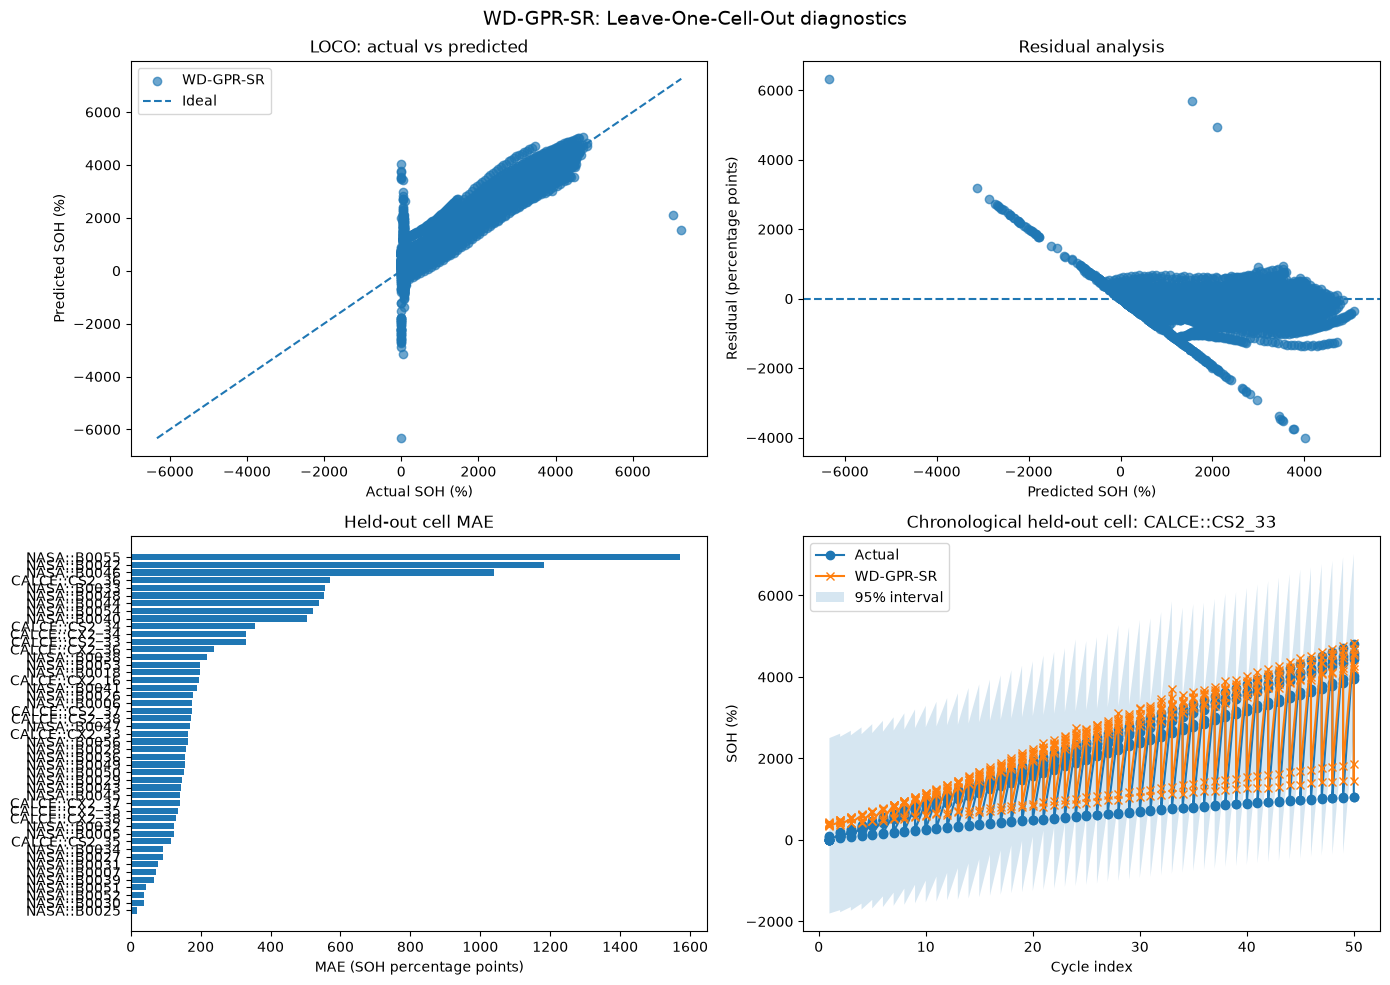

Symbolic residual ablation:


,variant,MAE,MSE,RMSE,R2,MAPE_pct,NLL,PICP_95_pct,MPIW_95
0,Wide-Deep sparse GP (no symbolic residual),121.829363,44925.458653,211.956266,0.973119,1.071899e+10,7.880362,100.000000,4065.298960
1,Full WD-GPR-SR,268.016023,186566.203848,431.933101,0.888368,3.655184e+10,8.219941,99.780143,6475.396637


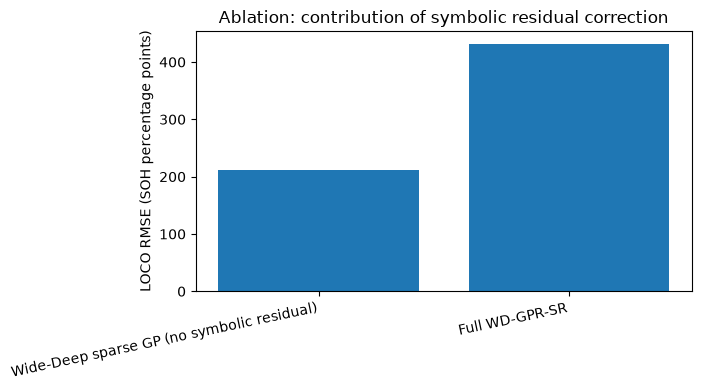

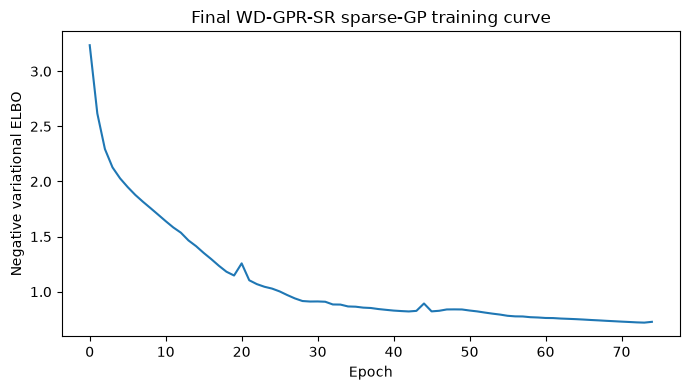

Saved diagnostic plots to: /home/raj/Documents/Projects/PBL/WD-GPR-SR/results


In [8]:
# Main out-of-fold diagnostic plots. All reported accuracy metrics use the outer LOCO predictions.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.scatter(oof['y_true_soh_pct'], oof['y_pred_soh_pct'], alpha=0.65, label='WD-GPR-SR')
lo = float(min(oof['y_true_soh_pct'].min(), oof['y_pred_soh_pct'].min()))
hi = float(max(oof['y_true_soh_pct'].max(), oof['y_pred_soh_pct'].max()))
ax.plot([lo, hi], [lo, hi], '--', label='Ideal')
ax.set_xlabel('Actual SOH (%)'); ax.set_ylabel('Predicted SOH (%)'); ax.set_title('LOCO: actual vs predicted'); ax.legend()

ax = axes[0, 1]
ax.scatter(oof['y_pred_soh_pct'], oof['residual'], alpha=0.65)
ax.axhline(0, linestyle='--')
ax.set_xlabel('Predicted SOH (%)'); ax.set_ylabel('Residual (percentage points)'); ax.set_title('Residual analysis')

cell_mae = oof.groupby('cell_group')['abs_error'].mean().sort_values()
ax = axes[1, 0]
ax.barh(cell_mae.index.astype(str), cell_mae.values)
ax.set_xlabel('MAE (SOH percentage points)'); ax.set_title('Held-out cell MAE')

ax = axes[1, 1]
first_cell = sorted(oof['cell_group'].unique())[0]
g = oof[oof['cell_group'] == first_cell].sort_values('cycle_index')
ax.plot(g['cycle_index'], g['y_true_soh_pct'], marker='o', label='Actual')
ax.plot(g['cycle_index'], g['y_pred_soh_pct'], marker='x', label='WD-GPR-SR')
ax.fill_between(
    g['cycle_index'].to_numpy(),
    (g['y_pred_soh_pct'] - 1.96 * g['y_std_soh_pct']).to_numpy(),
    (g['y_pred_soh_pct'] + 1.96 * g['y_std_soh_pct']).to_numpy(),
    alpha=0.18, label='95% interval'
)
ax.set_xlabel('Cycle index'); ax.set_ylabel('SOH (%)'); ax.set_title(f'Chronological held-out cell: {first_cell}'); ax.legend()

fig.suptitle('WD-GPR-SR: Leave-One-Cell-Out diagnostics', fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'loco_diagnostics.png', dpi=180)
plt.show()

# Ablation: same outer test folds, same fitted wide-deep GP, with vs without symbolic correction.
base_metrics = calculate_metrics(
    oof['y_true_soh_pct'],
    oof['y_pred_wd_gp_without_sr_soh_pct'],
    oof['y_std_wd_gp_without_sr_soh_pct'],
)
full_metrics = calculate_metrics(
    oof['y_true_soh_pct'], oof['y_pred_soh_pct'], oof['y_std_soh_pct']
)
ablation_table = pd.DataFrame([
    {'variant': 'Wide-Deep sparse GP (no symbolic residual)', **base_metrics},
    {'variant': 'Full WD-GPR-SR', **full_metrics},
])
ablation_table.to_csv(RESULTS_DIR / 'ablation_summary.csv', index=False)
print('Symbolic residual ablation:')
display(ablation_table)

plt.figure(figsize=(7, 4))
plt.bar(ablation_table['variant'], ablation_table['RMSE'])
plt.ylabel('LOCO RMSE (SOH percentage points)')
plt.title('Ablation: contribution of symbolic residual correction')
plt.xticks(rotation=12, ha='right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ablation_rmse.png', dpi=180)
plt.show()

# Final GP training curve from the all-data inference fit.
plt.figure(figsize=(7, 4))
plt.plot(final_fit['final_loss_history'])
plt.xlabel('Epoch'); plt.ylabel('Negative variational ELBO')
plt.title('Final WD-GPR-SR sparse-GP training curve')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'training_curve.png', dpi=180); plt.show()

print('Saved diagnostic plots to:', RESULTS_DIR)

## 8A. Optional kernel-branch ablations (additional compute)

The main ablation above removes the symbolic residual. This optional experiment separately removes the wide or deep covariance branch, using the same outer LOCO folds and preprocessing. It is disabled by default to avoid tripling the GP fitting workload; set `RUN_BRANCH_ABLATIONS = True` and execute this cell when you have time.

In [9]:
RUN_BRANCH_ABLATIONS = False

if RUN_BRANCH_ABLATIONS:
    branch_rows = []
    for fold_no, held_out_cell in enumerate(CELL_GROUPS, start=1):
        test_mask = cycles['cell_group'].astype(str).eq(held_out_cell)
        train_df = cycles.loc[~test_mask].copy().reset_index(drop=True)
        test_df = cycles.loc[test_mask].copy().reset_index(drop=True)
        _, y_scaler, X_train_2d, X_test_2d, y_train, _, y_test_raw, _ = transform_fold(train_df, test_df)

        for mode in ['wide_only', 'deep_only']:
            model, likelihood, _ = fit_sparse_wide_deep_gp(
                X_train_2d, y_train, seed=RANDOM_SEED,
                epochs=FINAL_GP_EPOCHS,
                n_inducing=min(NUM_INDUCING, len(X_train_2d)),
                kernel_mode=mode,
            )
            pred_scaled, std_scaled = predict_gp_distribution(model, likelihood, X_test_2d)
            pred = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
            std = np.maximum(std_scaled * float(y_scaler.scale_[0]), 1e-6)
            row = calculate_metrics(y_test_raw, pred, std)
            row.update({'fold': fold_no, 'held_out_cell': held_out_cell, 'kernel_variant': mode})
            branch_rows.append(row)
            del model, likelihood
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            print(f"fold {fold_no} | {mode} | RMSE={row['RMSE']:.4f}")

    branch_ablation = pd.DataFrame(branch_rows)
    branch_ablation.to_csv(RESULTS_DIR / 'kernel_branch_ablation.csv', index=False)
    branch_summary = branch_ablation.groupby('kernel_variant')[
        ['MAE', 'RMSE', 'R2', 'NLL', 'PICP_95_pct', 'MPIW_95']
    ].mean().reset_index()
    branch_summary.to_csv(RESULTS_DIR / 'kernel_branch_ablation_summary.csv', index=False)
    display(branch_summary)
else:
    print('Skipped. Set RUN_BRANCH_ABLATIONS=True to run wide-only and deep-only LOCO ablations.')

Skipped. Set RUN_BRANCH_ABLATIONS=True to run wide-only and deep-only LOCO ablations.


## 9. Explainability (XAI)

Includes selected-feature SHAP, LIME, PDP, ICE, deep-kernel ARD length scales, wide-branch relevance and finite-difference symbolic residual sensitivities. Explanations describe the final all-data fit; predictive metrics remain based on LOCO OOF data.

/home/raj/Documents/Projects/PBL/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


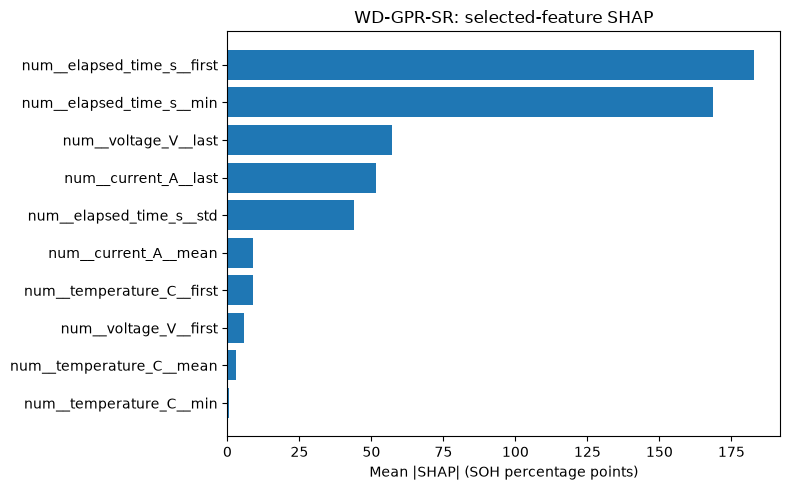

,feature_rule,local_weight
0,num__current_A__std <= -0.05,-502.593887
1,-0.95 < num__elapsed_time_s__first <= -0.07,-441.109100
2,-0.95 < num__elapsed_time_s__min <= -0.07,-284.421393
3,-0.95 < num__elapsed_time_s__mean <= -0.08,-245.212560
4,num__voltage_V__std <= -0.42,235.132133
5,num__nominal_capacity_Ah__last <= -0.52,182.675136
6,-0.96 < num__elapsed_time_s__max <= -0.10,-179.165306
7,num__temperature_C__last <= 0.05,-167.861116
8,num__elapsed_time_s__std > 0.31,-158.492699
9,num__nominal_capacity_Ah__first <= -0.52,149.408230


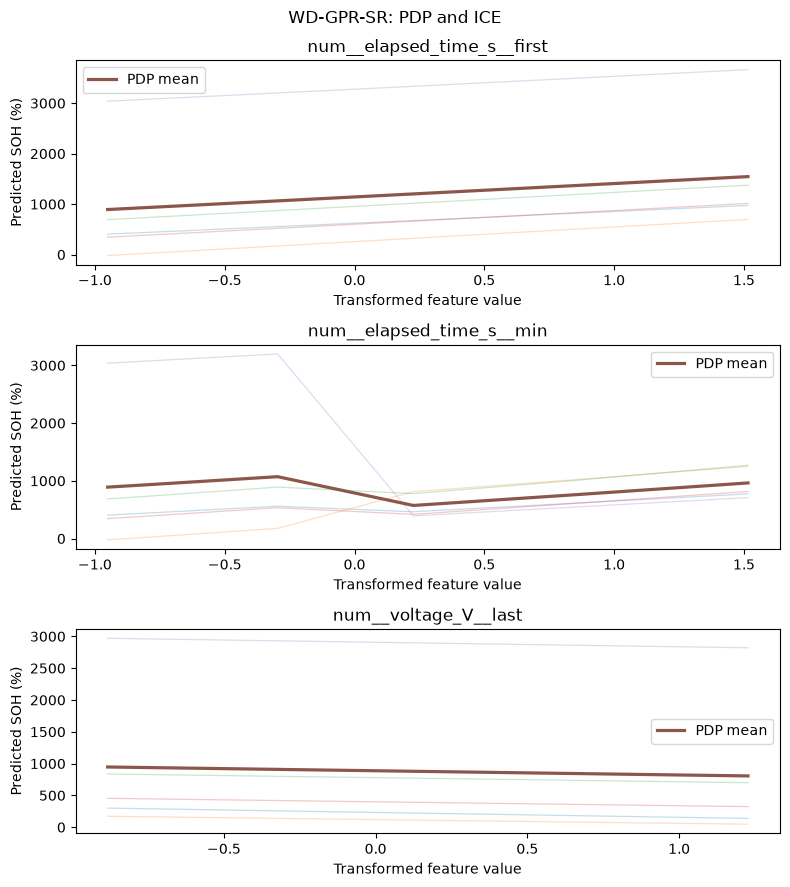

,deep_latent_dimension,length_scale,inverse_length_scale_relevance
7,latent_7,0.702217,1.424061
0,latent_0,0.703391,1.421685
10,latent_10,0.704932,1.418577
4,latent_4,0.713219,1.402094
1,latent_1,0.726771,1.375949
9,latent_9,0.727227,1.375087
6,latent_6,0.727901,1.373813
8,latent_8,0.728712,1.372285
5,latent_5,0.732961,1.364330
3,latent_3,0.734873,1.360779


,feature,wide_weight_norm
28,num__elapsed_time_s__first,0.431074
61,cat__battery_technology_UNKNOWN,0.403096
26,num__elapsed_time_s__min,0.343248
39,num__missingindicator_current_A__std,0.323215
24,num__elapsed_time_s__mean,0.312441
18,num__nominal_capacity_Ah__mean,0.306929
29,num__elapsed_time_s__last,0.303720
51,num__missingindicator_elapsed_time_s__mean,0.299130
20,num__nominal_capacity_Ah__min,0.294825
38,num__missingindicator_current_A__mean,0.290030


,symbolic_input,dr_dstandardized_input,abs_sensitivity
0,num__n_measurements,0.162136,0.162136
1,num__elapsed_time_s__max,0.000000,0.000000
2,num__elapsed_time_s__last,0.000000,0.000000
3,num__elapsed_time_s__mean,0.000000,0.000000
4,num__elapsed_time_s__min,0.000000,0.000000
5,num__elapsed_time_s__first,0.000000,0.000000
6,normalized_gp_predictive_std,0.000000,0.000000


XAI summary:


,method,status,details
0,SHAP,ok,Permutation SHAP on up to 10 high-variance tra...
1,LIME,ok,Local surrogate explanation for one representa...
2,PDP,ok,Partial dependence for top transformed features.
3,ICE,ok,Individual conditional expectation curves for ...
4,ARD length-scale relevance,ok,ARD relevance in learned deep latent dimension...
5,Symbolic equation sensitivities,ok,Finite-difference dr/dx; equation nodes=29.
6,Wide-branch relevance,ok,Norm of learned wide-branch weights per transf...


XAI outputs: /home/raj/Documents/Projects/PBL/WD-GPR-SR/results/xai


In [10]:
# Explainability on the final all-labelled-cell model. LOCO metrics above remain strictly OOF.
XAI_DIR = RESULTS_DIR / 'xai'
XAI_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
feature_names_xai = final_preprocessor.get_feature_names_out().tolist()


def predict_final_scaled_features(X):
    pred, std, gp_mean, gp_std, correction = predict_wd_gpr_sr(final_fit, X)
    return final_y_scaler.inverse_transform(pred.reshape(-1, 1)).ravel()


# 1. SHAP on a deterministic subset of up to 10 high-variance transformed features.
shap_importance = None
shap_status = 'unavailable'
lime_status = 'unavailable'
pdp_status = 'unavailable'
ice_status = 'unavailable'
ard_status = 'unavailable'
wide_status = 'unavailable'
try:
    import shap
    feature_var = np.nanvar(X_all_2d, axis=0)
    selected_xai = np.argsort(feature_var)[::-1][:min(10, X_all_2d.shape[1])]
    baseline = np.nanmedian(X_all_2d, axis=0).astype(np.float32)
    background_idx = rng.choice(len(X_all_2d), min(20, len(X_all_2d)), replace=False)
    explain_idx = rng.choice(len(X_all_2d), min(4, len(X_all_2d)), replace=False)

    def shap_predict_small(Xsmall):
        Xfull = np.repeat(baseline.reshape(1, -1), len(Xsmall), axis=0)
        Xfull[:, selected_xai] = np.asarray(Xsmall, dtype=np.float32)
        return predict_final_scaled_features(Xfull)

    bg_small = X_all_2d[background_idx][:, selected_xai]
    ex_small = X_all_2d[explain_idx][:, selected_xai]
    explainer = shap.PermutationExplainer(shap_predict_small, bg_small)
    shap_values = explainer(ex_small, max_evals=2 * len(selected_xai) + 1)
    sv = np.asarray(shap_values.values)
    if sv.ndim == 3:
        sv = sv.mean(axis=-1)
    shap_importance = np.mean(np.abs(sv), axis=0)
    shap_table = pd.DataFrame({
        'feature': [feature_names_xai[i] for i in selected_xai],
        'mean_abs_SHAP': shap_importance,
    }).sort_values('mean_abs_SHAP', ascending=False)
    shap_table.to_csv(XAI_DIR / 'shap_importance.csv', index=False)
    shap_status = 'ok'
    top = shap_table.sort_values('mean_abs_SHAP').tail(10)
    plt.figure(figsize=(8, 5)); plt.barh(top['feature'], top['mean_abs_SHAP'])
    plt.xlabel('Mean |SHAP| (SOH percentage points)'); plt.title('WD-GPR-SR: selected-feature SHAP')
    plt.tight_layout(); plt.savefig(XAI_DIR / 'shap_importance.png', dpi=170); plt.show()
except Exception as exc:
    shap_table = pd.DataFrame(columns=['feature', 'mean_abs_SHAP'])
    print('SHAP unavailable:', exc)


# 2. LIME local explanation.
try:
    if not hasattr(np, 'float'): np.float = float
    if not hasattr(np, 'int'): np.int = int
    from lime.lime_tabular import LimeTabularExplainer
    lime_bg = X_all_2d[rng.choice(len(X_all_2d), min(80, len(X_all_2d)), replace=False)]
    lime_explainer = LimeTabularExplainer(
        training_data=lime_bg,
        feature_names=feature_names_xai,
        mode='regression',
        discretize_continuous=True,
        random_state=RANDOM_SEED,
    )
    lime_local = lime_explainer.explain_instance(
        X_all_2d[0], predict_final_scaled_features,
        num_features=min(15, len(feature_names_xai)),
        num_samples=1200,
    )
    lime_table = pd.DataFrame(lime_local.as_list(), columns=['feature_rule', 'local_weight'])
    lime_table.to_csv(XAI_DIR / 'lime_local_explanation.csv', index=False)
    display(lime_table)
    lime_status = 'ok'
except Exception as exc:
    print('LIME unavailable:', exc)


# 3-4. PDP and ICE for the most influential available transformed features.
try:
    if shap_importance is not None:
        pdp_indices = selected_xai[np.argsort(shap_importance)[::-1][:3]]
    else:
        pdp_indices = np.argsort(np.nanvar(X_all_2d, axis=0))[::-1][:3]
    pdp_rows = []
    fig, axes = plt.subplots(len(pdp_indices), 1, figsize=(8, 3.0 * len(pdp_indices)), squeeze=False)
    local_rows = X_all_2d[rng.choice(len(X_all_2d), min(5, len(X_all_2d)), replace=False)]
    for ax, j in zip(axes.ravel(), pdp_indices):
        values = np.unique(np.quantile(X_all_2d[:, j], np.linspace(0.1, 0.9, 7)))
        if len(values) < 2:
            ax.set_visible(False); continue
        curves = []
        for base_row in local_rows:
            varied = np.repeat(base_row.reshape(1, -1), len(values), axis=0)
            varied[:, j] = values
            curves.append(predict_final_scaled_features(varied))
        curves = np.asarray(curves)
        for curve in curves:
            ax.plot(values, curve, alpha=0.25, linewidth=0.9)
        mean_curve = curves.mean(axis=0)
        ax.plot(values, mean_curve, linewidth=2.3, label='PDP mean')
        ax.set_title(feature_names_xai[j]); ax.set_xlabel('Transformed feature value')
        ax.set_ylabel('Predicted SOH (%)'); ax.legend()
        pdp_rows.append({'feature': feature_names_xai[j], 'pdp_prediction_range': float(mean_curve.max() - mean_curve.min())})
    fig.suptitle('WD-GPR-SR: PDP and ICE'); fig.tight_layout()
    fig.savefig(XAI_DIR / 'pdp_ice.png', dpi=170); plt.show()
    pd.DataFrame(pdp_rows).to_csv(XAI_DIR / 'pdp_ice_summary.csv', index=False)
    pdp_status = 'ok' if pdp_rows else 'unavailable'
    ice_status = 'ok' if pdp_rows else 'unavailable'
except Exception as exc:
    print('PDP/ICE unavailable:', exc)


# 5. ARD length-scale relevance in the learned deep latent space.
try:
    length_scales = final_model.deep_kernel.base_kernel.lengthscale.detach().cpu().numpy().reshape(-1)
    ard_table = pd.DataFrame({
        'deep_latent_dimension': [f'latent_{i}' for i in range(len(length_scales))],
        'length_scale': length_scales,
        'inverse_length_scale_relevance': 1.0 / np.maximum(length_scales, 1e-12),
    }).sort_values('inverse_length_scale_relevance', ascending=False)
    ard_table.to_csv(XAI_DIR / 'ard_latent_length_scales.csv', index=False)
    display(ard_table)
    ard_status = 'ok'
except Exception as exc:
    print('ARD relevance unavailable:', exc)

# Complementary wide-branch input relevance (weight norm per transformed input feature).
try:
    wide_weights = final_model.wide_branch.weight.detach().cpu().numpy()
    wide_relevance = np.linalg.norm(wide_weights, axis=0)
    wide_table = pd.DataFrame({
        'feature': feature_names_xai,
        'wide_weight_norm': wide_relevance,
    }).sort_values('wide_weight_norm', ascending=False)
    wide_table.to_csv(XAI_DIR / 'wide_branch_relevance.csv', index=False)
    display(wide_table.head(20))
    wide_status = 'ok'
except Exception as exc:
    print('Wide-branch relevance unavailable:', exc)


# 6. Symbolic residual equation and finite-difference sensitivities dr/dx.
sr_feature_names = [feature_names_xai[i] for i in final_fit['selected_indices']] + ['normalized_gp_predictive_std']
equation = symbolic_tree_expression(final_fit['symbolic_tree'], sr_feature_names)
node_count = count_tree_nodes(final_fit['symbolic_tree'])
with open(XAI_DIR / 'symbolic_residual_equation.txt', 'w', encoding='utf-8') as f:
    f.write(f'SOH_pct = target_mean + target_scale * (GP_mean_scaled + residual_equation)\n')
    f.write(f'residual_equation = {equation}\n')
    f.write(f'equation_node_count = {node_count}\n\n')
    f.write('Symbolic input mapping:\n')
    for i, name in enumerate(sr_feature_names):
        f.write(f'x{i} = {name}\n')

center = np.nanmedian(X_all_2d, axis=0).astype(np.float32).reshape(1, -1)
_, center_std = predict_gp_distribution(final_model, final_likelihood, center)
center_sr = make_symbolic_inputs(center, center_std, final_fit['selected_indices'], final_fit['uncertainty_scale'])
sens_rows = []
for pos, name in enumerate(sr_feature_names):
    eps = 0.05
    xp, xm = center_sr.copy(), center_sr.copy()
    xp[:, pos] += eps; xm[:, pos] -= eps
    deriv = float((evaluate_symbolic_tree(final_fit['symbolic_tree'], xp)[0] - evaluate_symbolic_tree(final_fit['symbolic_tree'], xm)[0]) / (2 * eps))
    sens_rows.append({'symbolic_input': name, 'dr_dstandardized_input': deriv, 'abs_sensitivity': abs(deriv)})
sensitivity_table = pd.DataFrame(sens_rows).sort_values('abs_sensitivity', ascending=False)
sensitivity_table.to_csv(XAI_DIR / 'symbolic_sensitivities.csv', index=False)
display(sensitivity_table)

xai_summary = pd.DataFrame([
    {'method': 'SHAP', 'status': shap_status, 'details': 'Permutation SHAP on up to 10 high-variance transformed features.'},
    {'method': 'LIME', 'status': lime_status, 'details': 'Local surrogate explanation for one representative cycle.'},
    {'method': 'PDP', 'status': pdp_status, 'details': 'Partial dependence for top transformed features.'},
    {'method': 'ICE', 'status': ice_status, 'details': 'Individual conditional expectation curves for representative cycles.'},
    {'method': 'ARD length-scale relevance', 'status': ard_status, 'details': 'ARD relevance in learned deep latent dimensions, not direct raw-feature length scales.'},
    {'method': 'Symbolic equation sensitivities', 'status': 'ok', 'details': f'Finite-difference dr/dx; equation nodes={node_count}.'},
    {'method': 'Wide-branch relevance', 'status': wide_status, 'details': 'Norm of learned wide-branch weights per transformed input.'},
])
xai_summary.to_csv(XAI_DIR / 'xai_summary.csv', index=False)
print('XAI summary:'); display(xai_summary)
print('XAI outputs:', XAI_DIR)

## 10. Final metrics and saved artifacts

In [11]:
metrics_for_display = [
    'MAE', 'MSE', 'RMSE', 'R2', 'MAPE_pct', 'NLL', 'PICP_95_pct', 'MPIW_95',
    'WD_GP_without_SR_MAE', 'WD_GP_without_SR_RMSE', 'WD_GP_without_SR_R2',
    'n_cells', 'n_cycles', 'seed', 'mean_fold_fit_time_s', 'total_loco_fit_time_s',
    'mean_predict_latency_ms_per_sample', 'full_fit_time_s',
    'inference_latency_ms_per_sample', 'model_artifact_size_MB',
    'host_process_RSS_MB_after_fit', 'equation_node_count',
]
metrics_table = pd.DataFrame([
    {'Metric': key, 'Value': overall_metrics.get(key, np.nan)}
    for key in metrics_for_display
])
print('FINAL OUT-OF-FOLD METRICS — SOH in original percentage units')
display(metrics_table)
print('\nFold-wise metrics:')
display(fold_metrics)
print('\nXAI summary:')
display(xai_summary)

with open(RESULTS_DIR / 'final_summary.json', 'w', encoding='utf-8') as f:
    json.dump(overall_metrics, f, indent=2, default=str)
metrics_table.to_csv(RESULTS_DIR / 'final_metrics_table.csv', index=False)
print('\nSaved model:', ARTIFACT_PATH)
print('Saved metrics, ablations and plots:', RESULTS_DIR)
print('Jetson latency/energy remain NaN until measured on the Jetson Orin Nano.')

# Compare against the already-computed baseline LOCO metrics without modifying them.
BASELINE_RESULTS_DIR = PROJECT_ROOT / 'baseline_results'
comparison_rows = []
for baseline_dir in sorted(BASELINE_RESULTS_DIR.iterdir()) if BASELINE_RESULTS_DIR.exists() else []:
    metrics_path = baseline_dir / 'metrics.json'
    if not metrics_path.exists() or not metrics_path.is_file():
        continue
    try:
        with open(metrics_path, 'r', encoding='utf-8') as f:
            baseline_metrics = json.load(f)
        comparison_rows.append({
            'model': baseline_metrics.get('model', baseline_dir.name),
            'MAE': baseline_metrics.get('MAE', np.nan),
            'RMSE': baseline_metrics.get('RMSE', np.nan),
            'R2': baseline_metrics.get('R2', np.nan),
            'MAPE_pct': baseline_metrics.get('MAPE_pct', np.nan),
            'NLL': baseline_metrics.get('NLL', np.nan),
            'PICP_95_pct': baseline_metrics.get('PICP_95_pct', np.nan),
            'MPIW_95': baseline_metrics.get('MPIW_95', np.nan),
        })
    except Exception as exc:
        print(f'Could not read {metrics_path}: {exc}')

comparison_rows.append({
    'model': 'WD-GPR-SR',
    'MAE': overall_metrics.get('MAE', np.nan),
    'RMSE': overall_metrics.get('RMSE', np.nan),
    'R2': overall_metrics.get('R2', np.nan),
    'MAPE_pct': overall_metrics.get('MAPE_pct', np.nan),
    'NLL': overall_metrics.get('NLL', np.nan),
    'PICP_95_pct': overall_metrics.get('PICP_95_pct', np.nan),
    'MPIW_95': overall_metrics.get('MPIW_95', np.nan),
})

baseline_comparison = pd.DataFrame(comparison_rows)
if not baseline_comparison.empty:
    baseline_comparison = baseline_comparison.sort_values('RMSE', na_position='last').reset_index(drop=True)
    baseline_comparison.insert(0, 'RMSE_rank', np.arange(1, len(baseline_comparison) + 1))
    baseline_comparison.to_csv(RESULTS_DIR / 'baseline_comparison.csv', index=False)
    print('LOCO comparison with existing baseline_results:')
    display(baseline_comparison)
else:
    print('No baseline metrics.json files found. Run the baseline notebooks first for comparison.')


FINAL OUT-OF-FOLD METRICS — SOH in original percentage units


,Metric,Value
0,MAE,2.680160e+02
1,MSE,1.865662e+05
2,RMSE,4.319331e+02
3,R2,8.883681e-01
4,MAPE_pct,3.655184e+10
5,NLL,8.219941e+00
6,PICP_95_pct,9.978014e+01
7,MPIW_95,6.475397e+03
8,WD_GP_without_SR_MAE,1.218294e+02
9,WD_GP_without_SR_RMSE,2.119563e+02



Fold-wise metrics:


,MAE,MSE,RMSE,R2,MAPE_pct,NLL,PICP_95_pct,MPIW_95,held_out_cell,fold,n_train_cycles,n_test_cycles,fit_time_s,predict_latency_ms_per_sample,WD_GP_without_SR_MAE,WD_GP_without_SR_RMSE,WD_GP_without_SR_R2,symbolic_equation_node_count,symbolic_status
0,329.140019,1.199012e+05,346.267509,0.930447,7.979004e+02,7.969145,100.000000,4300.284213,CALCE::CS2_33,1,8208,434,6.294824,0.015165,126.437839,156.815285,0.985735,3,gplearn
1,355.810051,2.869839e+05,535.708799,0.829954,7.655009e+01,8.214539,100.000000,5353.118587,CALCE::CS2_34,2,8235,407,6.090359,0.013692,341.472359,506.024344,0.848277,9,gplearn
2,115.521275,2.306138e+04,151.859724,0.984743,2.439500e+10,7.906591,100.000000,4204.132931,CALCE::CS2_35,3,8261,381,5.914340,0.014690,107.317113,143.799045,0.986319,6,gplearn
3,571.200822,4.210353e+05,648.872335,0.725976,7.256162e+10,8.307109,100.000000,5745.314106,CALCE::CS2_36,4,8139,503,5.049301,0.011535,142.092993,204.694690,0.972730,2,gplearn
4,175.458228,4.243509e+04,205.997783,0.971882,4.656153e+10,7.931124,100.000000,4274.859901,CALCE::CS2_37,5,8141,501,5.510448,0.011951,127.987851,179.430093,0.978667,3,gplearn
5,173.361425,5.575840e+04,236.132162,0.963651,1.447791e+10,8.212200,100.000000,5688.032115,CALCE::CS2_38,6,8140,502,5.830632,0.011883,178.939902,259.706943,0.956031,7,gplearn
6,195.998792,1.774242e+05,421.217510,0.853834,3.331615e+01,7.935631,100.000000,4288.940734,CALCE::CX2_16,7,8173,469,5.557143,0.011896,199.627065,424.468054,0.851569,4,gplearn
7,162.877693,6.755463e+04,259.912733,0.941698,1.829876e+01,9.486278,100.000000,20582.692528,CALCE::CX2_33,8,8220,422,5.657880,0.013961,171.906366,274.040815,0.935187,14,gplearn
8,329.999973,1.511136e+05,388.733289,0.887288,6.027511e+10,8.401768,100.000000,6794.049187,CALCE::CX2_34,9,8204,438,6.113134,0.013621,123.555227,173.929448,0.977436,12,gplearn
9,135.425443,3.850578e+04,196.228887,0.974277,2.968207e+01,8.344876,100.000000,6536.450446,CALCE::CX2_35,10,8186,456,6.335179,0.012806,73.314296,107.741289,0.992245,21,gplearn



XAI summary:


,method,status,details
0,SHAP,ok,Permutation SHAP on up to 10 high-variance tra...
1,LIME,ok,Local surrogate explanation for one representa...
2,PDP,ok,Partial dependence for top transformed features.
3,ICE,ok,Individual conditional expectation curves for ...
4,ARD length-scale relevance,ok,ARD relevance in learned deep latent dimension...
5,Symbolic equation sensitivities,ok,Finite-difference dr/dx; equation nodes=29.
6,Wide-branch relevance,ok,Norm of learned wide-branch weights per transf...



Saved model: /home/raj/Documents/Projects/PBL/models/wd_gpr_sr.joblib
Saved metrics, ablations and plots: /home/raj/Documents/Projects/PBL/WD-GPR-SR/results
Jetson latency/energy remain NaN until measured on the Jetson Orin Nano.
LOCO comparison with existing baseline_results:


,RMSE_rank,model,MAE,RMSE,R2,MAPE_pct,NLL,PICP_95_pct,MPIW_95
0,1,bilstm,45.034979,87.589667,0.995409,3.266160e+09,8.415713,81.728766,131.273640
1,2,wide_deep_nn,64.935330,175.200590,0.981634,1.964849e+09,11.466720,86.311039,296.211940
2,3,deep_nn,73.256129,175.444422,0.981582,5.371974e+09,7.830793,88.069891,285.838687
3,4,wide_nn,73.686062,179.181931,0.980789,2.576434e+09,11.728241,87.213608,318.987268
4,5,svr,79.017004,193.123996,0.977683,3.090667e+09,10.868709,87.190465,243.348169
5,6,gpr_matern,67.755301,193.976441,0.977486,1.048906e+09,7.048318,87.364036,379.840990
6,7,gpr_rbf,76.343791,196.584637,0.976876,1.848730e+09,6.898191,89.007174,432.432274
7,8,random_forest,95.986389,214.301571,0.972521,3.245541e+08,6.563545,93.994446,461.258927
8,9,sparse_gpr,78.594699,214.589170,0.972447,3.639903e+09,6.942425,92.652164,377.266072
9,10,xgboost,95.869610,218.164538,0.971521,1.864207e+09,22.837255,70.840083,157.551819
